# ILDC EDA

In [2]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ── Load all splits ──────────────────────────────────────────
splits = ['single_train','single_dev', 'multi_train', 'multi_dev', 'test', 'expert']
dfs = {}
for s in splits:
    dfs[s] = load_dataset("Exploration-Lab/IL-TUR", "cjpe", split=s).to_pandas()
    print(f"{s:15s} → {dfs[s].shape}  |  columns: {dfs[s].columns.tolist()}")

train = dfs['multi_train']
dev   = dfs['multi_dev']
test  = dfs['test']
expert = dfs['expert']

README.md: 0.00B [00:00, ?B/s]

cjpe/expert-00000-of-00001.parquet:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

cjpe/single_train-00000-of-00001.parquet:   0%|          | 0.00/56.4M [00:00<?, ?B/s]

cjpe/single_dev-00000-of-00001.parquet:   0%|          | 0.00/27.6M [00:00<?, ?B/s]

cjpe/multi_train-00000-of-00002.parquet:   0%|          | 0.00/234M [00:00<?, ?B/s]

cjpe/multi_train-00001-of-00002.parquet:   0%|          | 0.00/49.5M [00:00<?, ?B/s]

... (5 outputs left out)

Generating multi_train split:   0%|          | 0/32305 [00:00<?, ? examples/s]

Generating multi_dev split:   0%|          | 0/994 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1517 [00:00<?, ? examples/s]

single_train    → (5082, 8)  |  columns: ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']
single_dev      → (2511, 8)  |  columns: ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']
multi_train     → (32305, 8)  |  columns: ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']
multi_dev       → (994, 8)  |  columns: ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']
test            → (1517, 8)  |  columns: ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']
expert          → (56, 8)  |  columns: ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']


In [4]:
# ════════════════════════════════════════════════════════════
# EDA 1 — BASIC INSPECTION
# ════════════════════════════════════════════════════════════

print("="*50)
print("BASIC INSPECTION — multi_train")
print("="*50)

print(f"\nShape         : {train.shape}")
print(f"Columns       : {train.columns.tolist()}")
print(f"\nData types:\n{train.dtypes}")
print(f"\nNull values:\n{train.isnull().sum()}")
print(f"\nDuplicates    : {train.duplicated(subset=['text']).sum()}")
print(f"\nSample row:\n{train.iloc[0]}")

BASIC INSPECTION — multi_train

Shape         : (32305, 8)
Columns       : ['id', 'text', 'label', 'expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5']

Data types:
id          object
text        object
label        int64
expert_1    object
expert_2    object
expert_3    object
expert_4    object
expert_5    object
dtype: object

Null values:
id              0
text            0
label           0
expert_1    32305
expert_2    32305
expert_3    32305
expert_4    32305
expert_5    32305
dtype: int64

Duplicates    : 628

Sample row:
id                                                     2020_1
text         Uday Umesh Lalit, J. These appeals arise out ...
label                                                       0
expert_1                                                 None
expert_2                                                 None
expert_3                                                 None
expert_4                                                 None
expert_5               

In [5]:
# ════════════════════════════════════════════════════════════
# EDA 2 — LABEL DISTRIBUTION
# ════════════════════════════════════════════════════════════

print("="*50)
print("LABEL DISTRIBUTION")
print("="*50)

for name, df in dfs.items():
    counts = df['label'].value_counts().sort_index()
    pct    = df['label'].value_counts(normalize=True).sort_index() * 100
    print(f"\n{name}:")
    print(f"  Rejected (0) : {counts[0]:>6,}  ({pct[0]:.1f}%)")
    print(f"  Accepted (1) : {counts[1]:>6,}  ({pct[1]:.1f}%)")
    print(f"  Imbalance ratio : {counts.max()/counts.min():.2f}")

LABEL DISTRIBUTION

single_train:
  Rejected (0) :  3,147  (61.9%)
  Accepted (1) :  1,935  (38.1%)
  Imbalance ratio : 1.63

single_dev:
  Rejected (0) :  1,252  (49.9%)
  Accepted (1) :  1,259  (50.1%)
  Imbalance ratio : 1.01

multi_train:
  Rejected (0) : 18,920  (58.6%)
  Accepted (1) : 13,385  (41.4%)
  Imbalance ratio : 1.41

multi_dev:
  Rejected (0) :    497  (50.0%)
  Accepted (1) :    497  (50.0%)
  Imbalance ratio : 1.00

test:
  Rejected (0) :    755  (49.8%)
  Accepted (1) :    762  (50.2%)
  Imbalance ratio : 1.01

expert:
  Rejected (0) :     27  (48.2%)
  Accepted (1) :     29  (51.8%)
  Imbalance ratio : 1.07


In [6]:
# ════════════════════════════════════════════════════════════
# EDA 3 — TEXT LENGTH ANALYSIS
# ════════════════════════════════════════════════════════════

for name, df in dfs.items():
    df['word_count']  = df['text'].apply(lambda x: len(str(x).split()))
    df['char_count']  = df['text'].apply(lambda x: len(str(x)))

print("\nWord count stats — multi_train:")
print(train['word_count'].describe().round(0))

print("\nWord count by label:")
print(train.groupby('label')['word_count'].describe().round(0))

# How many exceed BERT's 512 token limit (~384 words)
over_limit = (train['word_count'] > 384).sum()
print(f"\nDocs exceeding ~512 tokens : {over_limit:,} ({over_limit/len(train)*100:.1f}%)")


Word count stats — multi_train:
count     32305.0
mean       3161.0
std        6433.0
min          35.0
25%         920.0
50%        2035.0
75%        3735.0
max      412606.0
Name: word_count, dtype: float64

Word count by label:
         count    mean     std   min    25%     50%     75%       max
label                                                                
0      18920.0  3238.0  6988.0  37.0  871.0  2014.0  3756.0  396206.0
1      13385.0  3052.0  5554.0  35.0  986.0  2060.0  3702.0  412606.0

Docs exceeding ~512 tokens : 28,801 (89.2%)


In [7]:
# ════════════════════════════════════════════════════════════
# EDA 4 — SPURIOUS CUE ANALYSIS  ← core of your project
# ════════════════════════════════════════════════════════════
import re

spurious_patterns = {
    'IPC sections'   : r'\bSection\s+\d+[A-Z]?\s*(IPC|CrPC)\b',
    'Judge names'    : r'\b[A-Z]\.\s+[A-Z][a-z]+,\s*J\.?\b',
    'Court names'    : r'\b(Supreme Court|High Court)\b',
    'Leave granted'  : r'\bLeave\s+granted\b',
    'SLP'            : r'\bSLP\b',
    'Case numbers'   : r'\b(Civil|Criminal)\s+Appeal\s+No\.',
}

print(f"\n{'Cue':<20} {'Prevalence':>12} {'Acc(Present)':>14} {'Acc(Absent)':>13} {'Gap':>8}")
print("─" * 72)

for cue, pattern in spurious_patterns.items():
    col = f'has_{cue}'
    train[col] = train['text'].str.contains(pattern, regex=True, case=False, na=False)

    prev  = train[col].mean() * 100
    r_yes = train[train[col]]['label'].mean() * 100
    r_no  = train[~train[col]]['label'].mean() * 100
    gap   = abs(r_yes - r_no)
    flag  = " ← SHORTCUT" if gap > 10 else ""

    print(f"{cue:<20} {prev:>11.1f}% {r_yes:>13.1f}% {r_no:>12.1f}% {gap:>7.1f}%{flag}")


Cue                    Prevalence   Acc(Present)   Acc(Absent)      Gap
────────────────────────────────────────────────────────────────────────


/tmp/ipykernel_189/2991811687.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  train[col] = train['text'].str.contains(pattern, regex=True, case=False, na=False)


IPC sections                 8.2%          43.8%         41.2%     2.6%
Judge names                 23.7%          41.0%         41.6%     0.6%


/tmp/ipykernel_189/2991811687.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  train[col] = train['text'].str.contains(pattern, regex=True, case=False, na=False)


Court names                 88.0%          41.7%         39.2%     2.5%
Leave granted               30.7%          49.8%         37.7%    12.1% ← SHORTCUT
SLP                          9.8%          41.1%         41.5%     0.3%


/tmp/ipykernel_189/2991811687.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  train[col] = train['text'].str.contains(pattern, regex=True, case=False, na=False)


Case numbers                30.3%          40.7%         41.8%     1.1%


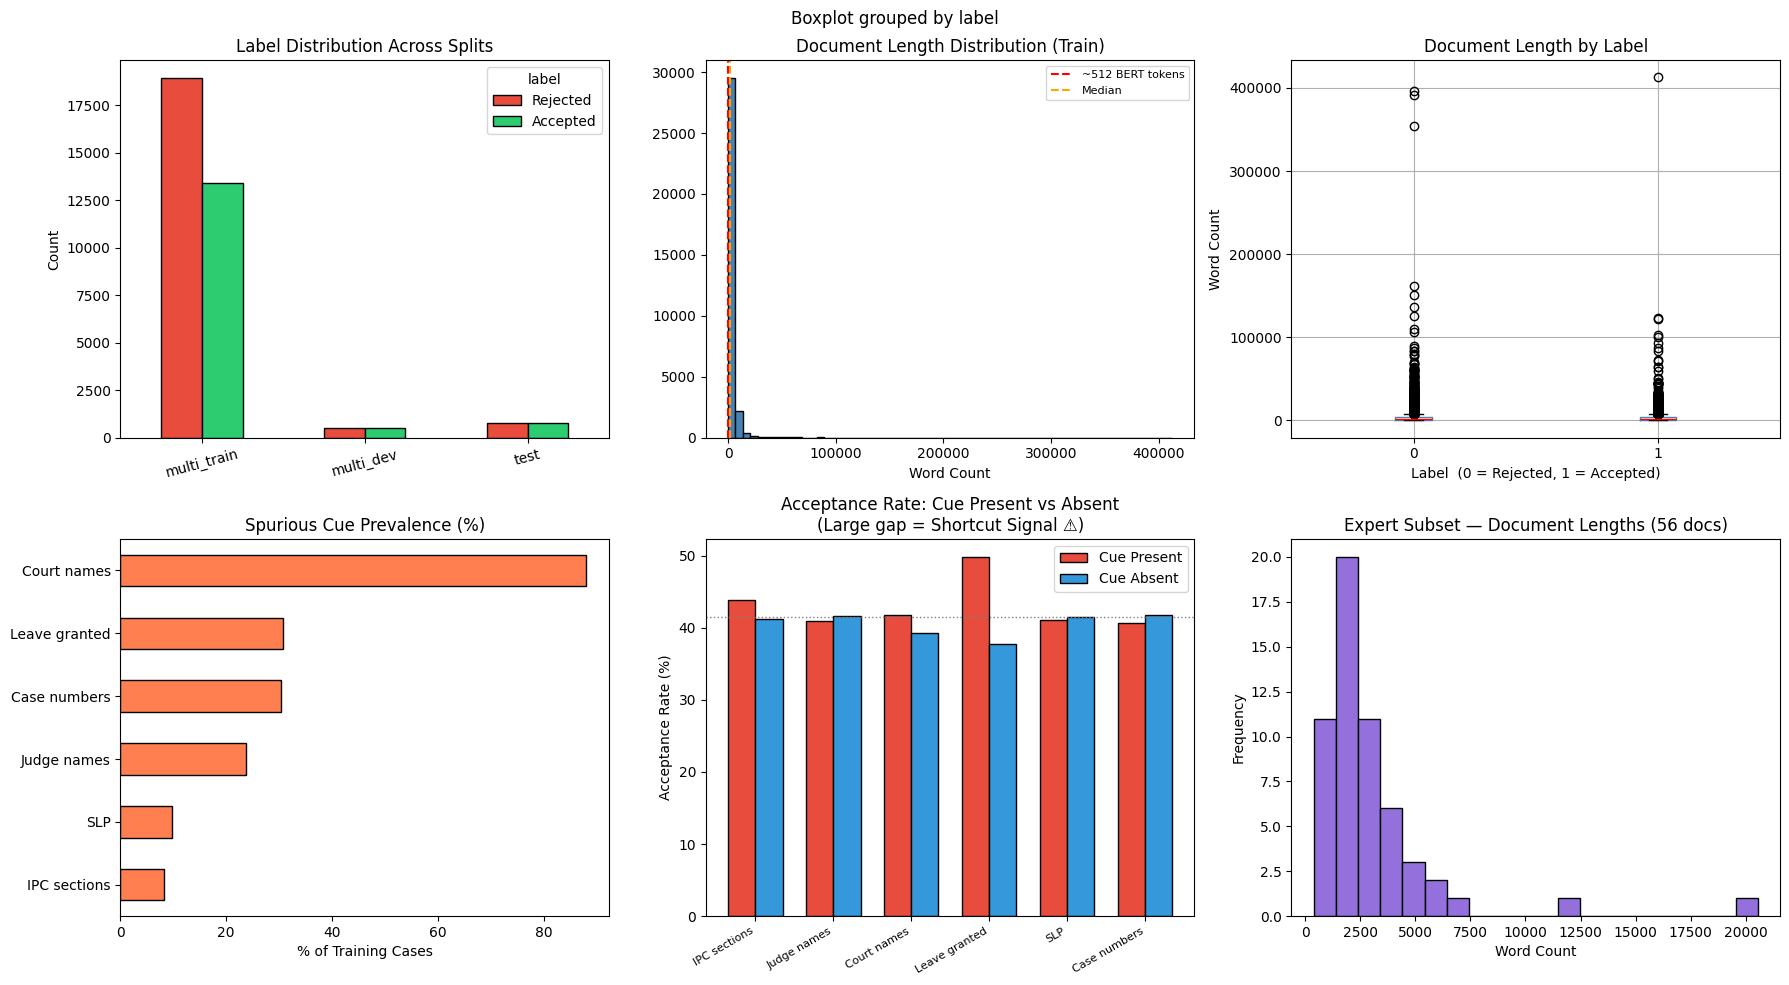

Saved: ildc_eda.png


In [8]:
# ════════════════════════════════════════════════════════════
# EDA 5 — PLOTS
# ════════════════════════════════════════════════════════════

spurious_cols = [c for c in train.columns if c.startswith('has_')]
cue_names     = [c.replace('has_', '') for c in spurious_cols]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('ILDC Multi — Exploratory Data Analysis', fontsize=14, fontweight='bold')

# 1. Label distribution across splits
split_labels = {k: dfs[k]['label'].value_counts().sort_index() for k in ['multi_train','multi_dev','test']}
pd.DataFrame(split_labels).T.rename(columns={0:'Rejected',1:'Accepted'}).plot(
    kind='bar', ax=axes[0,0], color=['#e74c3c','#2ecc71'], edgecolor='black')
axes[0,0].set_title('Label Distribution Across Splits')
axes[0,0].tick_params(axis='x', rotation=15)
axes[0,0].set_ylabel('Count')

# 2. Word count distribution
axes[0,1].hist(train['word_count'], bins=60, color='steelblue', edgecolor='black')
axes[0,1].axvline(384,  color='red',    linestyle='--', linewidth=1.5, label='~512 BERT tokens')
axes[0,1].axvline(train['word_count'].median(), color='orange', linestyle='--', linewidth=1.5, label='Median')
axes[0,1].set_title('Document Length Distribution (Train)')
axes[0,1].set_xlabel('Word Count')
axes[0,1].legend(fontsize=8)

# 3. Word count by label (box plot)
train.boxplot(column='word_count', by='label', ax=axes[0,2],
              boxprops=dict(color='steelblue'),
              medianprops=dict(color='red'))
axes[0,2].set_title('Document Length by Label')
axes[0,2].set_xlabel('Label  (0 = Rejected, 1 = Accepted)')
axes[0,2].set_ylabel('Word Count')
plt.sca(axes[0,2]); plt.title('Document Length by Label')

# 4. Spurious cue prevalence
(train[spurious_cols].mean()*100).rename(lambda x: x.replace('has_','')).sort_values().plot(
    kind='barh', ax=axes[1,0], color='coral', edgecolor='black')
axes[1,0].set_title('Spurious Cue Prevalence (%)')
axes[1,0].set_xlabel('% of Training Cases')

# 5. Acceptance rate — cue present vs absent (KEY PLOT)
r_pres = [train[train[f'has_{c}']]['label'].mean()*100 for c in cue_names]
r_abs  = [train[~train[f'has_{c}']]['label'].mean()*100 for c in cue_names]
x = np.arange(len(cue_names)); w = 0.35
axes[1,1].bar(x-w/2, r_pres, w, label='Cue Present', color='#e74c3c', edgecolor='black')
axes[1,1].bar(x+w/2, r_abs,  w, label='Cue Absent',  color='#3498db', edgecolor='black')
axes[1,1].set_xticks(x)
axes[1,1].set_xticklabels(cue_names, rotation=30, ha='right', fontsize=8)
axes[1,1].set_title('Acceptance Rate: Cue Present vs Absent\n(Large gap = Shortcut Signal ⚠)')
axes[1,1].set_ylabel('Acceptance Rate (%)')
axes[1,1].legend()
axes[1,1].axhline(train['label'].mean()*100, color='gray',
                   linestyle=':', linewidth=1, label='Overall avg')

# 6. Expert split — word count
expert['word_count'].plot(kind='hist', bins=20, ax=axes[1,2],
                           color='mediumpurple', edgecolor='black')
axes[1,2].set_title('Expert Subset — Document Lengths (56 docs)')
axes[1,2].set_xlabel('Word Count')

plt.tight_layout()
plt.savefig('ildc_eda.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: ildc_eda.png")



---


# Summary of EDA

Dataset structure : 8 cols (id, text, label, expert_1 to expert_5)

Null values in the expert cols for the multi and single train datasets (expected).

Mild label imbalance in multi_train.

Text length


1.   Average 3,161 words but max is 412,606 words —> extreme outliers exist
2.   89.2% of docs exceed BERT's 512 token limit —> you cannot just truncate, you need a proper chunking strategy

628 duplicate texts must be removed before training


Spurious cues analysis (pre-training evidence of shortcuts)


*   "Leave granted" is your only confirmed shortcut: 12.1% gap (49.8% acceptance when present vs 37.7% when absent)

*   All others (IPC sections, judge names, court names, SLP) have gaps under 3%
— weak signals on the full dataset

but this makes sense because criminal cases aren't filtered out yet.


---





# ILDC Pre-processing

In [3]:
# ════════════════════════════════════════
# STEP 1: Remove duplicates
# ════════════════════════════════════════
print(f"Before: {len(train):,}")
train = train.drop_duplicates(subset=['text']).reset_index(drop=True)
print(f"After removing duplicates: {len(train):,}")

Before: 32,305
After removing duplicates: 31,677


In [4]:
# ════════════════════════════════════════
# STEP 2: Drop expert columns (all null in multi_train)
# ════════════════════════════════════════
train = train[['id', 'text', 'label']]
train = train.dropna(subset=['text', 'label']).reset_index(drop=True)
print(f"After null drop : {len(train):,}")

After null drop : 31,677


In [5]:
# ════════════════════════════════════════
# STEP 3: Filter criminal cases
# ════════════════════════════════════════

# Tier 1: Case header — highest precision
tier1 = train['text'].str.contains(
    r'Criminal Appeal|Criminal Writ Petition|Crl\.?\s*A\b',
    case=False, na=False, regex=True
)

# Tier 2: Strong criminal-only terms
tier2 = train['text'].str.contains(
    r'\bSessions\s+(Case|Judge|Court)\b'
    r'|\bSection\s+30[234567]\b'
    r'|\bSection\s+376\b'
    r'|\bdeath\s+sentence\b'
    r'|\blife\s+imprisonment\b'
    r'|\bacquitted\b'
    r'|\bcharge\s*sheet\b',
    case=False, na=False, regex=True
)

# Exclude known false positives
exclude = train['text'].str.contains(
    r'compulsory retirement|service matter'
    r'|disciplinary proceed|departmental proceed'
    r'|food adulteration|Prevention of Food'
    r'|Article\s+105|Article\s+226',
    case=False, na=False, regex=True
)

criminal_df = train[(tier1 | tier2) & ~exclude].copy().reset_index(drop=True)

print(f"Total train           : {len(train):,}")
print(f"Tier 1 (header)       : {tier1.sum():,}")
print(f"Tier 2 (strong terms) : {tier2.sum():,}")
print(f"Excluded              : {((tier1 | tier2) & exclude).sum():,}")
print(f"\nFinal criminal subset : {len(criminal_df):,} ({len(criminal_df)/len(train)*100:.1f}%)")
print(f"  Rejected (0) : {(criminal_df['label']==0).sum():,} ({(criminal_df['label']==0).mean()*100:.1f}%)")
print(f"  Accepted (1) : {(criminal_df['label']==1).sum():,} ({(criminal_df['label']==1).mean()*100:.1f}%)")

# Spot check
print("\n--- Spot check (5 random cases) ---")
for _, row in criminal_df.sample(5, random_state=42).iterrows():
    print(f"\nID: {row['id']} | Label: {row['label']}")
    print(f"{str(row['text'])[:300]}")
    print("-"*60)

/tmp/ipykernel_1830/3048772734.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  tier2 = train['text'].str.contains(


Total train           : 31,677
Tier 1 (header)       : 3,938
Tier 2 (strong terms) : 7,063
Excluded              : 708

Final criminal subset : 7,094 (22.4%)
  Rejected (0) : 4,095 (57.7%)
  Accepted (1) : 2,999 (42.3%)

--- Spot check (5 random cases) ---

ID: 1999_925 | Label: 1
 PATTANAIK,J. The State of Kerala is in appeal against the Judgment dated 4.2.94 of the Kerala High Court in Criminal Revision Petition No. 521 of 1988. By the impugned Judgment, the High Court in revision, has interfered with the companyviction and sentence passed against the accused respondent of 
------------------------------------------------------------

ID: 1984_336 | Label: 0
CRIMINAL APPELLATE JURISDICTION Criminal Appeal Nos. 461-466 of 1980. From the Judgment order dated 9.11.78 of the Allahabad High Court in Criminal Misc. Application Nos. 1655, 1656, 1657, 1691 and 1698 of 1979. AND Special Leave Petition Nos. 903-908 of 1984 Dalveer Bhandari H.M. Singh for the appe
------------------------------

In [6]:
# ════════════════════════════════════════
# STEP 4: Handle BERT 512 token limit
# ════════════════════════════════════════
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("law-ai/InLegalBERT")

# 3a: Calculate token counts on full text
print("Calculating token counts...")
criminal_df['token_count'] = criminal_df['text'].apply(
    lambda x: len(tokenizer(
        str(x),
        truncation=False,
        add_special_tokens=True
    )['input_ids'])
)

print(f"\nDocs within 512 tokens : {(criminal_df['token_count'] <= 512).sum():,} ({(criminal_df['token_count'] <= 512).mean()*100:.1f}%)")
print(f"Docs exceeding 512     : {(criminal_df['token_count'] > 512).sum():,} ({(criminal_df['token_count'] > 512).mean()*100:.1f}%)")

# 3b: Head truncation for fine-tuning
# Spurious cues (Criminal Appeal, Leave granted, judge names)
# are in opening lines → head truncation preserves them
# Full text is preserved separately for OpenNyAI + XAI
def truncate_to_512(text):
    tokens = tokenizer(
        str(text),
        truncation=True,
        max_length=512,
        add_special_tokens=True,
        return_tensors=None
    )
    return tokenizer.decode(tokens['input_ids'], skip_special_tokens=True)

print("\nCreating truncated version...")
criminal_df['text_truncated'] = criminal_df['text'].apply(truncate_to_512)

criminal_df['token_count_truncated'] = criminal_df['text_truncated'].apply(
    lambda x: len(tokenizer(str(x), add_special_tokens=True)['input_ids'])
)
print(f"Max tokens after truncation : {criminal_df['token_count_truncated'].max()}")
print(f"All within 512              : {(criminal_df['token_count_truncated'] <= 512).all()}")

# 3c: Retention check — verify cues survive truncation
print("\n--- Spurious cue retention after truncation ---")
print(f"{'Cue':<20} {'Full text':>10} {'Truncated':>10} {'Retention':>12}")
print("─" * 56)

cue_checks = {
    'Criminal Appeal' : r'Criminal Appeal',
    'Leave granted'   : r'\bLeave\s+granted\b',
    'Judge names'     : r'\b[A-Z]\.\s+[A-Z][a-z]+,\s*J\.?\b',
    'IPC sections'    : r'\bSection\s+\d+[A-Z]?\s*(IPC|CrPC)\b',
    'SLP'             : r'\bSLP\b',
}

for cue, pattern in cue_checks.items():
    in_full  = criminal_df['text'].str.contains(
        pattern, regex=True, case=False, na=False).sum()
    in_trunc = criminal_df['text_truncated'].str.contains(
        pattern, regex=True, case=False, na=False).sum()
    retention = (in_trunc / in_full * 100) if in_full > 0 else 0
    flag = " ⚠ IN BODY TOO" if retention < 80 else " ✓"
    print(f"{cue:<20} {in_full:>10,} {in_trunc:>10,} {retention:>11.1f}%{flag}")

config.json:   0%|          | 0.00/671 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/516 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (30627 > 512). Running this sequence through the model will result in indexing errors


Calculating token counts...

Docs within 512 tokens : 458 (6.5%)
Docs exceeding 512     : 6,636 (93.5%)

Creating truncated version...
Max tokens after truncation : 512
All within 512              : True

--- Spurious cue retention after truncation ---
Cue                   Full text  Truncated    Retention
────────────────────────────────────────────────────────
Criminal Appeal           3,477      3,067        88.2% ✓
Leave granted             1,764      1,695        96.1% ✓
Judge names               1,777      1,772        99.7% ✓


/tmp/ipykernel_1830/81374895.py:58: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  in_full  = criminal_df['text'].str.contains(
/tmp/ipykernel_1830/81374895.py:60: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  in_trunc = criminal_df['text_truncated'].str.contains(


IPC sections              2,354      1,338        56.8% ⚠ IN BODY TOO
SLP                         602        420        69.8% ⚠ IN BODY TOO


In [9]:
# ════════════════════════════════════════
# STEP 4: Create spurious-masked version
# (for ablation Phase 2)
# ════════════════════════════════════════
import re

MASK = "[MASK]"

def mask_spurious_cues(text):
    t = str(text)
    # IPC/CrPC section references
    t = re.sub(r'\bSection\s+\d+[A-Z]?\s*(IPC|CrPC)\b', MASK, t, flags=re.IGNORECASE)
    # Judge names
    t = re.sub(r'\b[A-Z]\.\s+[A-Z][a-z]+,\s*J\.?\b', MASK, t)
    # Case numbers
    t = re.sub(r'Criminal Appeal No\.?\s*[\d/]+', MASK, t, flags=re.IGNORECASE)
    # SLP references
    t = re.sub(r'\bSLP\s*\(?\s*Crl\.?\s*\)?\s*No\.?\s*[\d/]+', MASK, t, flags=re.IGNORECASE)
    # Leave granted
    t = re.sub(r'\bLeave\s+granted\.?', MASK, t, flags=re.IGNORECASE)
    return t

print("Creating spurious-masked version...")
criminal_df['text_spurious_masked'] = criminal_df['text'].apply(mask_spurious_cues)

# Verify
sample_orig   = criminal_df['text'].iloc[0][:400]
sample_masked = criminal_df['text_spurious_masked'].iloc[0][:400]
print("\nOriginal (first 400 chars):")
print(sample_orig)
print("\nAfter masking:")
print(sample_masked)

Creating spurious-masked version...

Original (first 400 chars):
 Indira Banerjee, J. These appeals are against the judgment and order dated 21.11.2006 passed by the Madurai Bench of Madras High Court, allowing Criminal Appeal Nos. 834, 835, 836, 895, 926, 934 and Signature Not Verified 938 of 1998, setting aside the judgment and order dated Digitally signed by JAYANT KUMAR ARORA 6.10.1998 of companyviction passed by the Additional Sessions Judge, Date 2020.02.

After masking:
 Indira Banerjee, J. These appeals are against the judgment and order dated 21.11.2006 passed by the Madurai Bench of Madras High Court, allowing Criminal Appeal Nos. 834, 835, 836, 895, 926, 934 and Signature Not Verified 938 of 1998, setting aside the judgment and order dated Digitally signed by JAYANT KUMAR ARORA 6.10.1998 of companyviction passed by the Additional Sessions Judge, Date 2020.02.



Cue                  Prevalence   Acc(Present)   Acc(Absent)      Gap
──────────────────────────────────────────────────────────────────────
Criminal Appeal           49.0%          41.7%         42.8%     1.1%


/tmp/ipykernel_1830/2037058541.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  criminal_df[col] = criminal_df['text'].str.contains(


IPC sections              33.2%          43.7%         41.6%     2.1%
Judge names               25.0%          40.3%         42.9%     2.6%


/tmp/ipykernel_1830/2037058541.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  criminal_df[col] = criminal_df['text'].str.contains(


Court names               95.0%          42.6%         36.8%     5.7%
Leave granted             24.9%          51.9%         39.1%    12.8% ← SHORTCUT
SLP                        8.5%          43.9%         42.1%     1.7%
Sessions Court            15.2%          40.5%         42.6%     2.1%


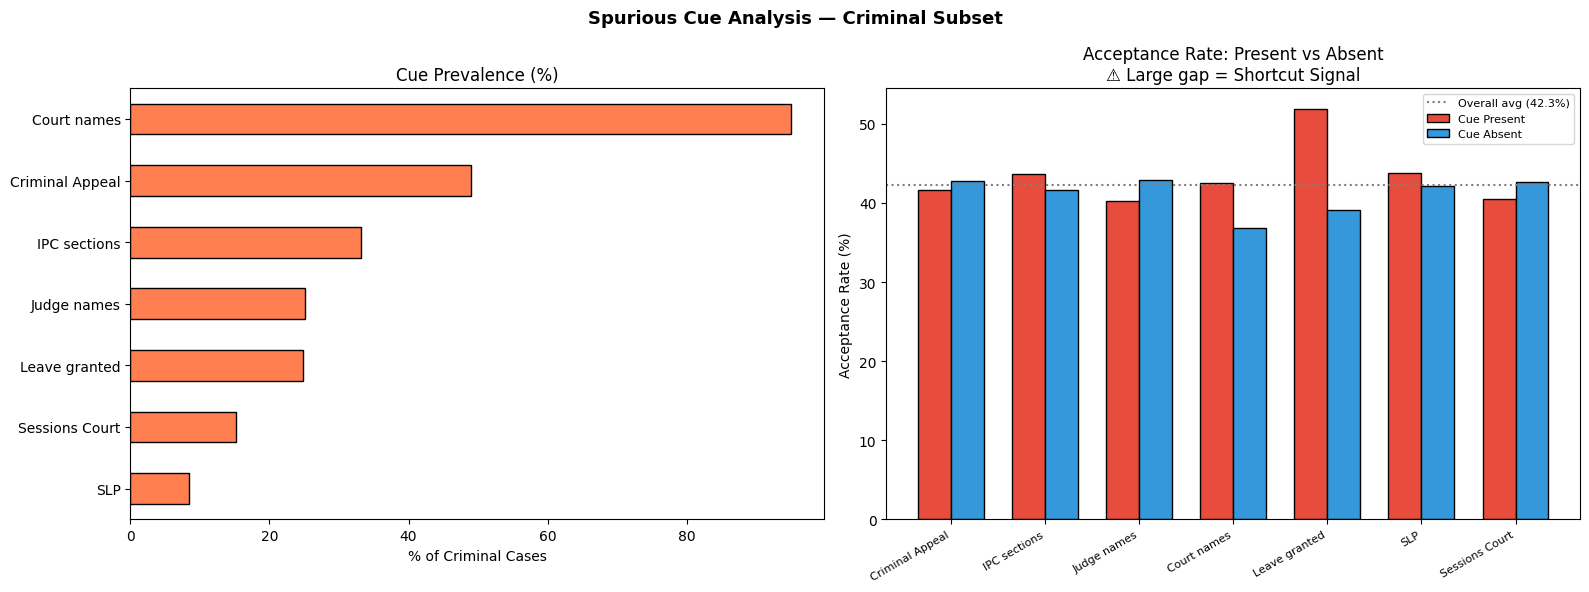

In [10]:
# ════════════════════════════════════════
# STEP 5: Spurious cue analysis
# on criminal subset (full text)
# ════════════════════════════════════════

spurious_patterns = {
    'Criminal Appeal' : r'Criminal Appeal',
    'IPC sections'    : r'\bSection\s+\d+[A-Z]?\s*(IPC|CrPC)\b',
    'Judge names'     : r'\b[A-Z]\.\s+[A-Z][a-z]+,\s*J\.?\b',
    'Court names'     : r'\b(Supreme Court|High Court)\b',
    'Leave granted'   : r'\bLeave\s+granted\b',
    'SLP'             : r'\bSLP\b',
    'Sessions Court'  : r'\bSessions\s+Court\b',
}

print(f"\n{'Cue':<20} {'Prevalence':>10} {'Acc(Present)':>14} {'Acc(Absent)':>13} {'Gap':>8}")
print("─" * 70)

results = []
for cue, pattern in spurious_patterns.items():
    col = f'has_{cue}'
    criminal_df[col] = criminal_df['text'].str.contains(
        pattern, regex=True, case=False, na=False)
    prev  = criminal_df[col].mean() * 100
    r_yes = criminal_df[criminal_df[col]]['label'].mean() * 100
    r_no  = criminal_df[~criminal_df[col]]['label'].mean() * 100
    gap   = abs(r_yes - r_no)
    flag  = " ← SHORTCUT" if gap > 10 else ""
    results.append({'cue': cue, 'prev': prev,
                    'r_present': r_yes, 'r_absent': r_no, 'gap': gap})
    print(f"{cue:<20} {prev:>9.1f}% {r_yes:>13.1f}% "
          f"{r_no:>12.1f}% {gap:>7.1f}%{flag}")

# Plot
spurious_cols = [f"has_{c}" for c in spurious_patterns]
cue_names     = list(spurious_patterns.keys())
r_pres_list   = [r['r_present'] for r in results]
r_abs_list    = [r['r_absent']  for r in results]
overall_acc   = criminal_df['label'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Spurious Cue Analysis — Criminal Subset', fontsize=13, fontweight='bold')

(criminal_df[spurious_cols].mean()*100)\
    .rename(lambda x: x.replace('has_',''))\
    .sort_values()\
    .plot(kind='barh', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Cue Prevalence (%)')
axes[0].set_xlabel('% of Criminal Cases')

x = np.arange(len(cue_names)); w = 0.35
axes[1].bar(x-w/2, r_pres_list, w, label='Cue Present', color='#e74c3c', edgecolor='black')
axes[1].bar(x+w/2, r_abs_list,  w, label='Cue Absent',  color='#3498db', edgecolor='black')
axes[1].axhline(overall_acc, color='gray', linestyle=':',
                linewidth=1.5, label=f'Overall avg ({overall_acc:.1f}%)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(cue_names, rotation=30, ha='right', fontsize=8)
axes[1].set_title('Acceptance Rate: Present vs Absent\n⚠ Large gap = Shortcut Signal')
axes[1].set_ylabel('Acceptance Rate (%)')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('spurious_cues_criminal.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# ════════════════════════════════════════
# STEP 6: Save — parquet to avoid
# CSV comma issues with legal text
# ════════════════════════════════════════

# Drop has_ columns before saving
has_cols = [c for c in criminal_df.columns if c.startswith('has_')]
save_df  = criminal_df.drop(columns=has_cols)

save_cols = [
    'id', 'label',
    'text',                   # full text → OpenNyAI + XAI
    'text_truncated',         # 512 tokens → fine-tuning
    'text_spurious_masked',   # cues masked → ablation
    'token_count',
    'token_count_truncated'
]

save_df[save_cols].to_parquet('ildc_criminal_final.parquet', index=False)

# Verify
df_check = pd.read_parquet('ildc_criminal_final.parquet')
print("="*50)
print("PREPROCESSING COMPLETE")
print("="*50)
print(f"Total cases             : {len(df_check):,}")
print(f"  Rejected (0)          : {(df_check['label']==0).sum():,}")
print(f"  Accepted (1)          : {(df_check['label']==1).sum():,}")
print(f"Columns saved           : {df_check.columns.tolist()}")
print(f"Avg tokens (original)   : {df_check['token_count'].mean():.0f}")
print(f"Avg tokens (truncated)  : {df_check['token_count_truncated'].mean():.0f}")
print(f"\nFile: ildc_criminal_final.parquet ✓")
print(f"\nNext step → Fine-tune InLegalBERT on text_truncated + label")

PREPROCESSING COMPLETE
Total cases             : 7,094
  Rejected (0)          : 4,095
  Accepted (1)          : 2,999
Columns saved           : ['id', 'label', 'text', 'text_truncated', 'text_spurious_masked', 'token_count', 'token_count_truncated']
Avg tokens (original)   : 4058
Avg tokens (truncated)  : 499

File: ildc_criminal_final.parquet ✓

Next step → Fine-tune InLegalBERT on text_truncated + label


In [12]:
import pandas as pd

# ════════════════════════════════════════
# VERIFY parquet file
# ════════════════════════════════════════

df = pd.read_parquet('ildc_criminal_final.parquet')

# 1. Basic shape and columns
print("Shape   :", df.shape)
print("Columns :", df.columns.tolist())
print("\nDtypes:\n", df.dtypes)

# 2. No data loss
print(f"\nNull values:\n{df.isnull().sum()}")

# 3. Label distribution intact
print(f"\nLabel distribution:")
print(f"  Rejected (0) : {(df['label']==0).sum():,}")
print(f"  Accepted (1) : {(df['label']==1).sum():,}")

# 4. Check all 3 text versions are present and non-empty
print(f"\nText versions check:")
print(f"  text                : {df['text'].notna().sum():,} non-null, avg {df['text'].str.len().mean():.0f} chars")
print(f"  text_truncated      : {df['text_truncated'].notna().sum():,} non-null, avg {df['text_truncated'].str.len().mean():.0f} chars")
print(f"  text_spurious_masked: {df['text_spurious_masked'].notna().sum():,} non-null, avg {df['text_spurious_masked'].str.len().mean():.0f} chars")

# 5. Token counts look right
print(f"\nToken counts:")
print(f"  Original  — avg: {df['token_count'].mean():.0f}, max: {df['token_count'].max()}")
print(f"  Truncated — avg: {df['token_count_truncated'].mean():.0f}, max: {df['token_count_truncated'].max()}")
print(f"  All truncated within 512: {(df['token_count_truncated'] <= 512).all()}")

# 6. Spot check — read one full case manually
print("\n--- Sample case (row 0) ---")
row = df.iloc[0]
print(f"ID             : {row['id']}")
print(f"Label          : {row['label']}")
print(f"\nFull text (first 300 chars):\n{row['text'][:300]}")
print(f"\nTruncated (first 300 chars):\n{row['text_truncated'][:300]}")
print(f"\nSpurious masked (first 300 chars):\n{row['text_spurious_masked'][:300]}")

# 7. Verify masking actually removed cues
import re
masked_still_has_ipc = df['text_spurious_masked'].str.contains(
    r'\bSection\s+\d+[A-Z]?\s*(IPC|CrPC)\b', regex=True, case=False, na=False).sum()
masked_still_has_leave = df['text_spurious_masked'].str.contains(
    r'\bLeave\s+granted\b', regex=True, case=False, na=False).sum()

print(f"\nMasking verification:")
print(f"  IPC refs still in masked text  : {masked_still_has_ipc} (should be 0)")
print(f"  'Leave granted' still in masked: {masked_still_has_leave} (should be 0)")

Shape   : (7094, 7)
Columns : ['id', 'label', 'text', 'text_truncated', 'text_spurious_masked', 'token_count', 'token_count_truncated']

Dtypes:
 id                       object
label                     int64
text                     object
text_truncated           object
text_spurious_masked     object
token_count               int64
token_count_truncated     int64
dtype: object

Null values:
id                       0
label                    0
text                     0
text_truncated           0
text_spurious_masked     0
token_count              0
token_count_truncated    0
dtype: int64

Label distribution:
  Rejected (0) : 4,095
  Accepted (1) : 2,999

Text versions check:
  text                : 7,094 non-null, avg 18456 chars
  text_truncated      : 7,094 non-null, avg 2165 chars
  text_spurious_masked: 7,094 non-null, avg 18424 chars

Token counts:
  Original  — avg: 4058, max: 214826
  Truncated — avg: 499, max: 512
  All truncated within 512: True

--- Sample case (row 0) -

/tmp/ipykernel_1830/3130903938.py:45: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  masked_still_has_ipc = df['text_spurious_masked'].str.contains(



Masking verification:
  IPC refs still in masked text  : 0 (should be 0)
  'Leave granted' still in masked: 0 (should be 0)
